In [1]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score,
    f1_score
)

train_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
test_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "Income"
]

train_raw = pd.read_csv(
    train_url, names=columns, skipinitialspace=True,
    na_values="?", header=None
)

test_raw = pd.read_csv(
    test_url, names=columns, skipinitialspace=True,
    na_values="?", header=None, skiprows=1
)

train_raw["Income"] = train_raw["Income"].astype(str).str.strip()
test_raw["Income"] = (
    test_raw["Income"].astype(str)
    .str.replace(".", "", regex=False).str.strip()
)

print("Số lượng dữ liệu huấn luyện:", len(train_raw))
print("Số lượng dữ liệu kiểm thử:", len(test_raw))

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Số lượng dữ liệu huấn luyện: 32561
Số lượng dữ liệu kiểm thử: 16281


In [2]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

train = train_raw.dropna().copy()
test = test_raw.dropna().copy()

train = train.drop(columns=["fnlwgt"], errors="ignore")
test = test.drop(columns=["fnlwgt"], errors="ignore")

n_train = len(train)
n_test = len(test)

data = pd.concat([train, test], ignore_index=True)

print("Số dòng huấn luyện sau xử lý:", n_train)
print("Số dòng kiểm thử sau xử lý:", n_test)
print("Kích thước dữ liệu sau khi nối:", data.shape)
display(data.head())

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Số dòng huấn luyện sau xử lý: 30162
Số dòng kiểm thử sau xử lý: 15060
Kích thước dữ liệu sau khi nối: (45222, 14)


,age,workclass,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,Income
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008


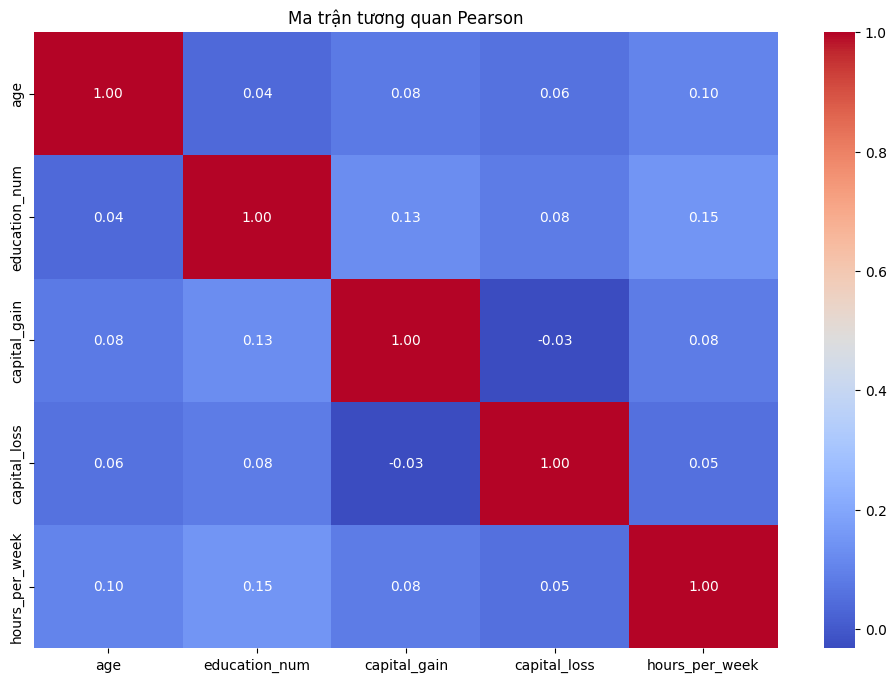

Các cột bị loại bỏ: []
Kích thước dữ liệu sau khi khảo sát Pearson: (45222, 14)


In [3]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

numeric_data = data.select_dtypes(include=np.number)

corr = numeric_data.corr(method="pearson")

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Ma trận tương quan Pearson")
plt.show()

columns_to_drop = set()

for i in range(len(corr.columns)):
    for j in range(i):
        if abs(corr.iloc[i, j]) > 0.9:
            col = corr.columns[i]
            if col != "Income":
                columns_to_drop.add(col)

data = data.drop(columns=list(columns_to_drop), errors="ignore")

print("Các cột bị loại bỏ:", list(columns_to_drop))
print("Kích thước dữ liệu sau khi khảo sát Pearson:", data.shape)

In [4]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

features = data.drop(columns=["Income"])
labels = data["Income"]

print("Các thuộc tính Features:")
display(features.head())

print("Thuộc tính quyết định Labels:")
display(labels.head())

print("Kích thước Features:", features.shape)
print("Kích thước Labels:", labels.shape)

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Các thuộc tính Features:


,age,workclass,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


Thuộc tính quyết định Labels:


,Income
0,<=50K
1,<=50K
2,<=50K
3,<=50K
4,<=50K


Kích thước Features: (45222, 13)
Kích thước Labels: (45222,)


In [5]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

features_encoded = pd.get_dummies(features)

print("Dữ liệu sau khi chuyển đổi One-hot:")
display(features_encoded.head())

print("Kích thước dữ liệu trước chuyển đổi:", features.shape)
print("Kích thước dữ liệu sau chuyển đổi:", features_encoded.shape)

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Dữ liệu sau khi chuyển đổi One-hot:


,age,education_num,capital_gain,capital_loss,hours_per_week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native_country_Portugal,native_country_Puerto-Rico,native_country_Scotland,native_country_South,native_country_Taiwan,native_country_Thailand,native_country_Trinadad&Tobago,native_country_United-States,native_country_Vietnam,native_country_Yugoslavia
0,39,13,2174,0,40,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,50,13,0,0,13,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
2,38,9,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
3,53,7,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
4,28,13,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False


Kích thước dữ liệu trước chuyển đổi: (45222, 13)
Kích thước dữ liệu sau chuyển đổi: (45222, 103)


In [6]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

X_train = features_encoded.iloc[:n_train]
X_test = features_encoded.iloc[n_train:]

y_train = labels.iloc[:n_train]
y_test = labels.iloc[n_train:]

print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước y_test:", y_test.shape)

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Kích thước X_train: (30162, 103)
Kích thước X_test: (15060, 103)
Kích thước y_train: (30162,)
Kích thước y_test: (15060,)


Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn ID3:
[[10026  1334]
 [ 1441  2259]]

Báo cáo phân loại ID3:
              precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.63      0.61      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.81      0.82      0.81     15060

Accuracy: 0.8157370517928287
Precision: 0.8139919959517652
Recall: 0.8157370517928287


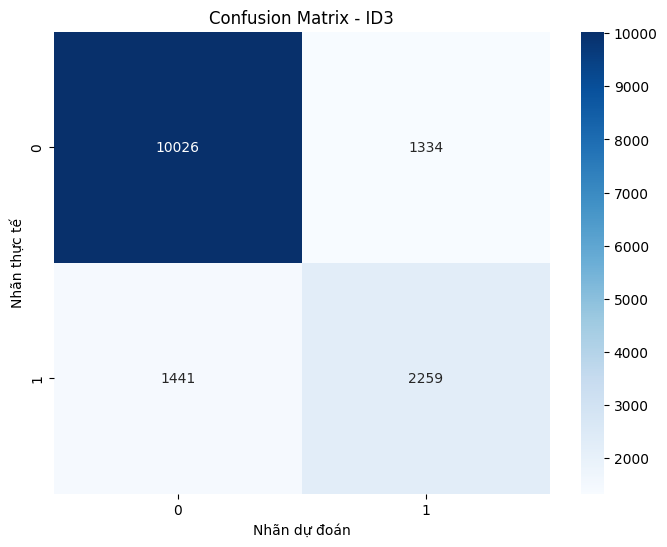

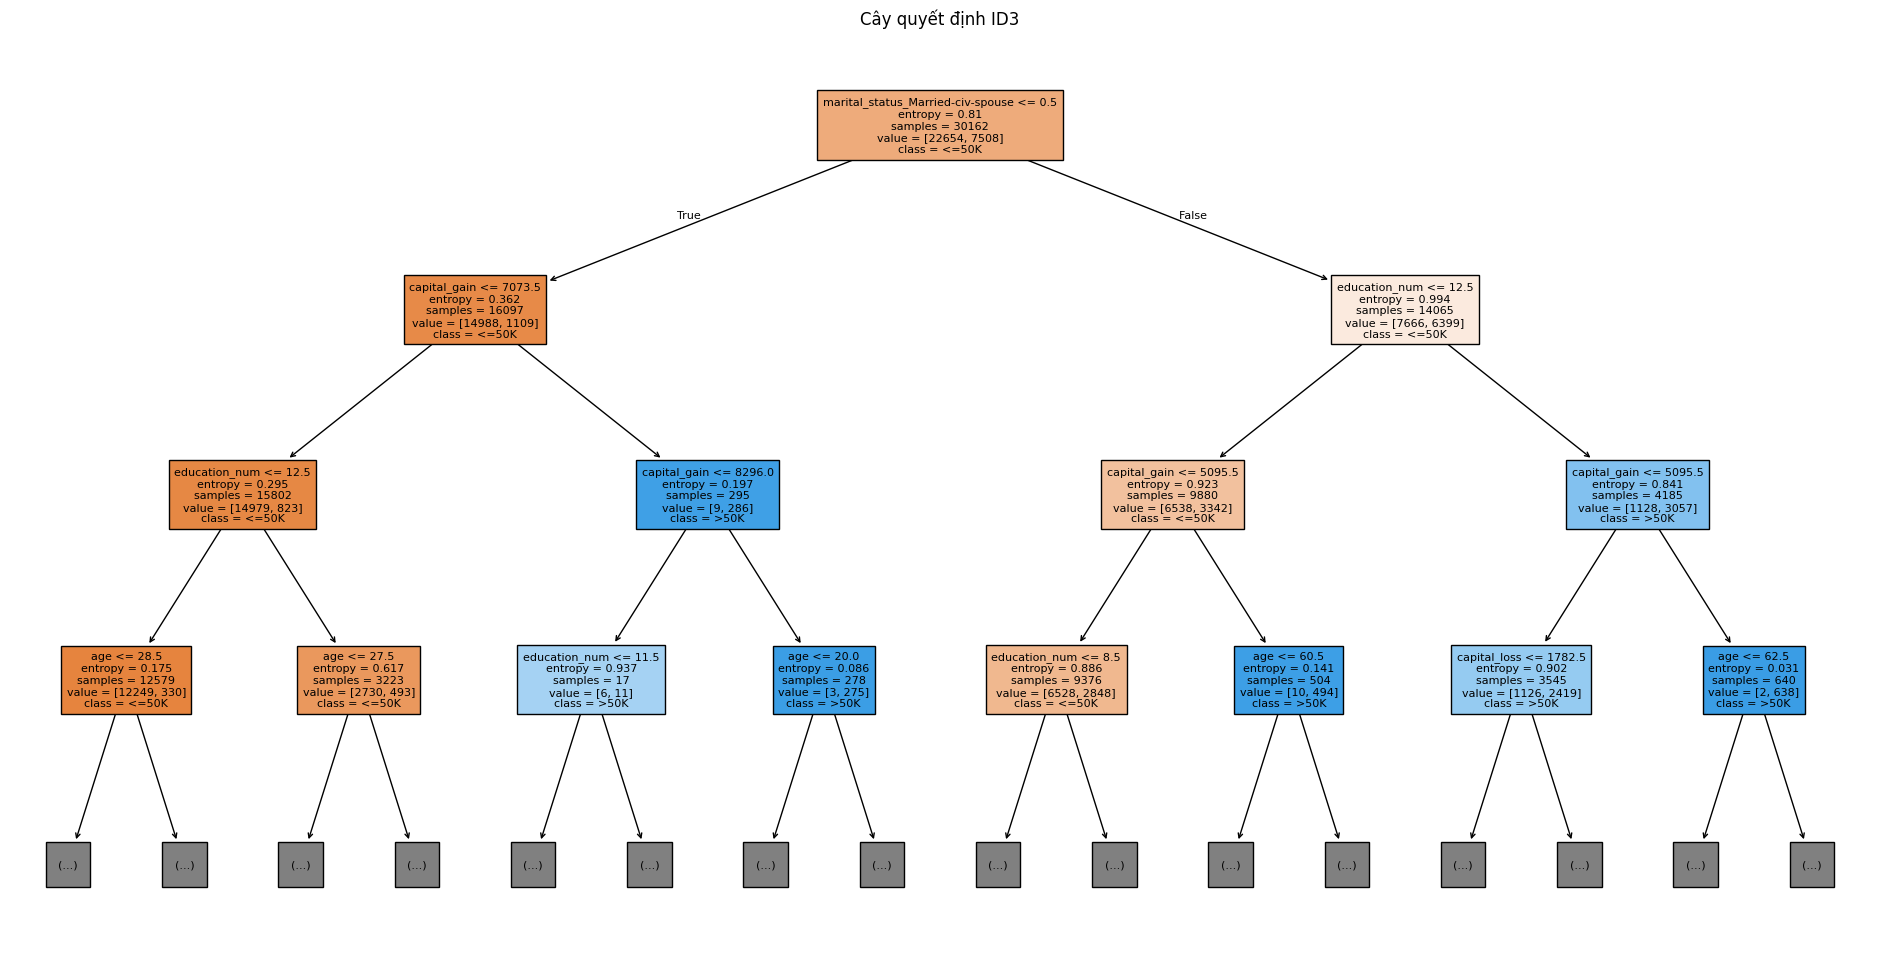

In [7]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

id3_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

id3_model.fit(X_train, y_train)

y_pred_id3 = id3_model.predict(X_test)

print("Ma trận nhầm lẫn ID3:")
cm_id3 = confusion_matrix(y_test, y_pred_id3)
print(cm_id3)

print("\nBáo cáo phân loại ID3:")
print(classification_report(y_test, y_pred_id3))

print("Accuracy:", accuracy_score(y_test, y_pred_id3))
print("Precision:", precision_score(
    y_test, y_pred_id3, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_id3, average="weighted", zero_division=0
))

plt.figure(figsize=(8, 6))
sns.heatmap(cm_id3, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - ID3")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

plt.figure(figsize=(24, 12))
plot_tree(
    id3_model,
    feature_names=X_train.columns,
    class_names=id3_model.classes_,
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title("Cây quyết định ID3")
plt.savefig("decision_tree_ID3.png", dpi=100, bbox_inches="tight")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn CART:
[[10006  1354]
 [ 1463  2237]]

Báo cáo phân loại CART:
              precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.75     15060
weighted avg       0.81      0.81      0.81     15060

Accuracy: 0.8129482071713148
Precision: 0.8111424514089618
Recall: 0.8129482071713148


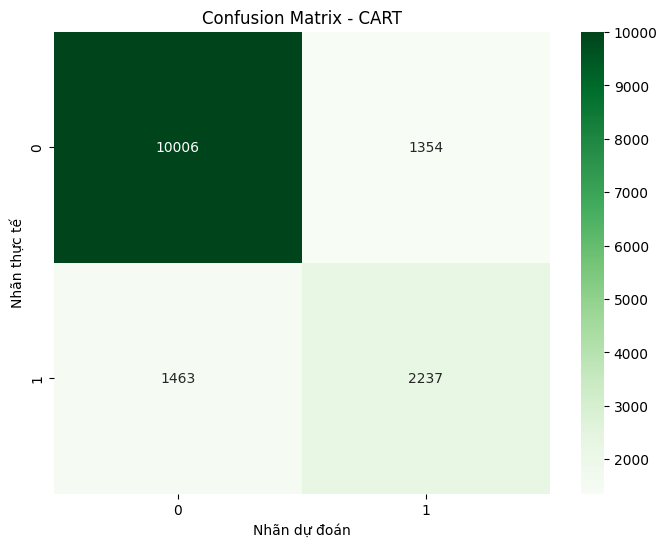

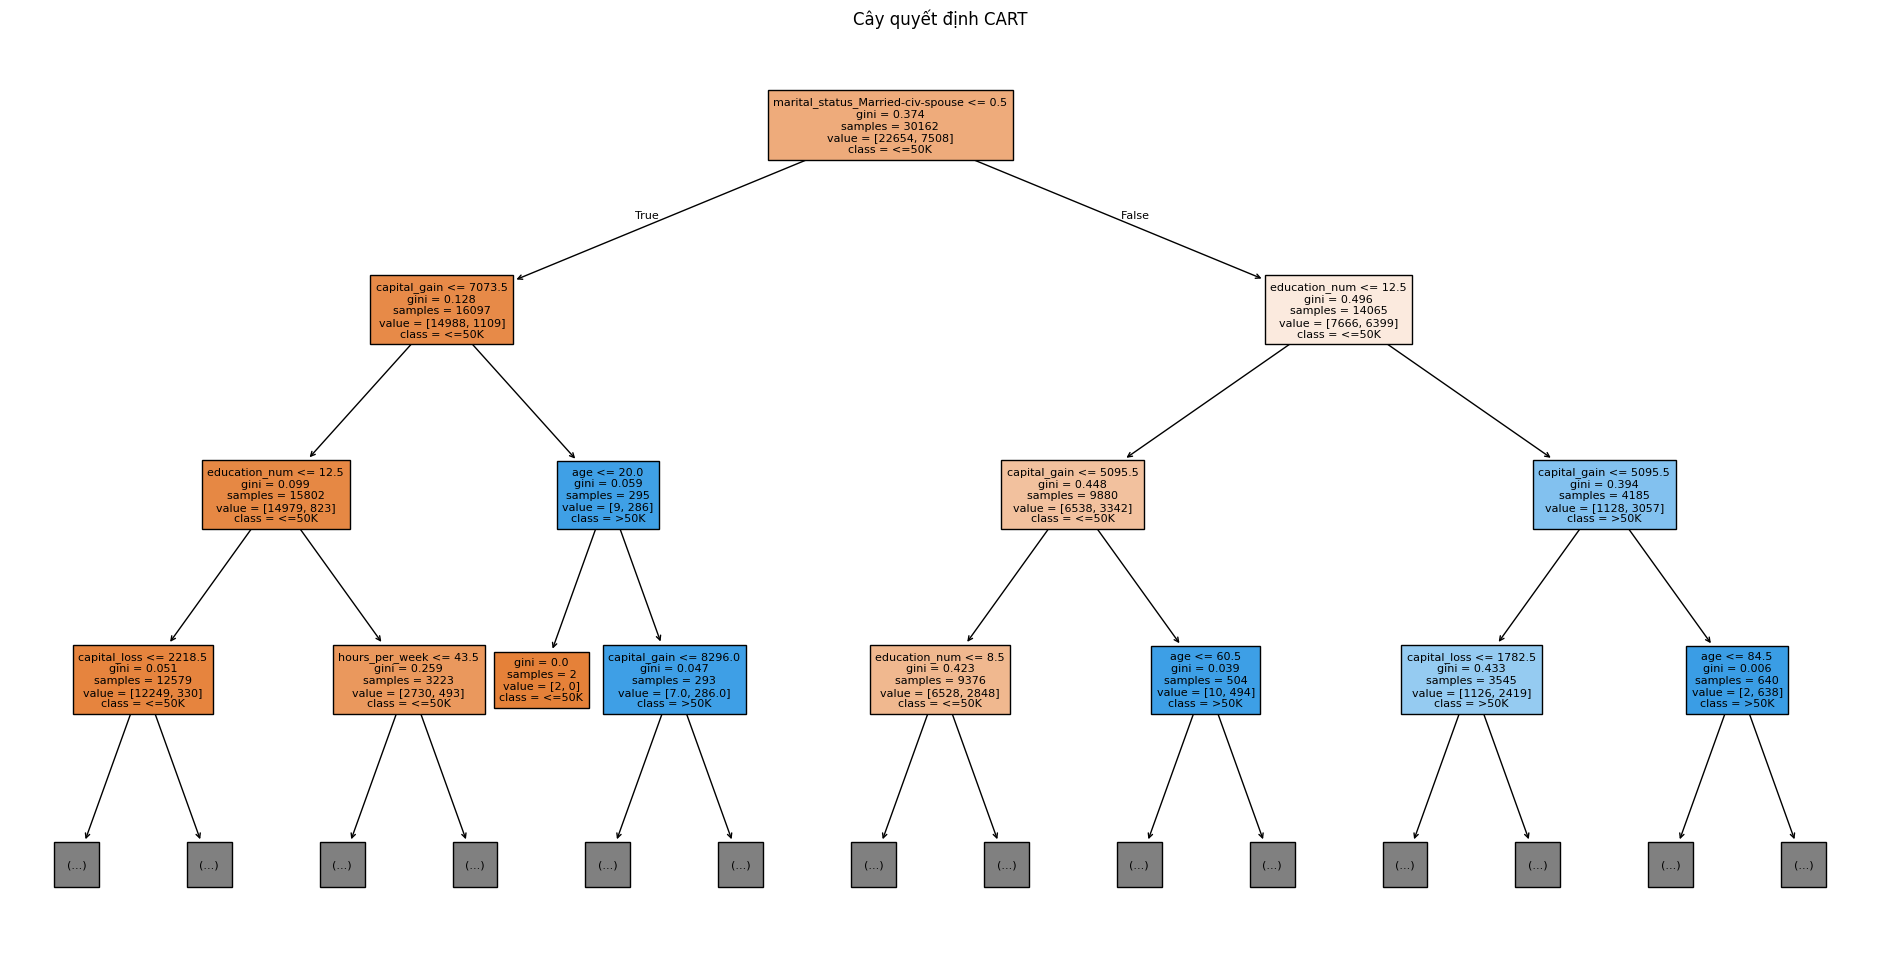

In [8]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

cart_model.fit(X_train, y_train)

y_pred_cart = cart_model.predict(X_test)

print("Ma trận nhầm lẫn CART:")
cm_cart = confusion_matrix(y_test, y_pred_cart)
print(cm_cart)

print("\nBáo cáo phân loại CART:")
print(classification_report(y_test, y_pred_cart))

print("Accuracy:", accuracy_score(y_test, y_pred_cart))
print("Precision:", precision_score(
    y_test, y_pred_cart, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_cart, average="weighted", zero_division=0
))

plt.figure(figsize=(8, 6))
sns.heatmap(cm_cart, annot=True, fmt="d", cmap="Greens")
plt.title("Confusion Matrix - CART")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

plt.figure(figsize=(24, 12))
plot_tree(
    cart_model,
    feature_names=X_train.columns,
    class_names=cart_model.classes_,
    filled=True,
    max_depth=3,
    fontsize=8
)
plt.title("Cây quyết định CART")
plt.savefig("decision_tree_CART.png", dpi=100, bbox_inches="tight")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008
Ma trận nhầm lẫn Naïve Bayes:
[[9073 2287]
 [ 681 3019]]

Báo cáo phân loại Naïve Bayes:
              precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060

Accuracy: 0.8029216467463479
Precision: 0.8414404769455701
Recall: 0.8029216467463479


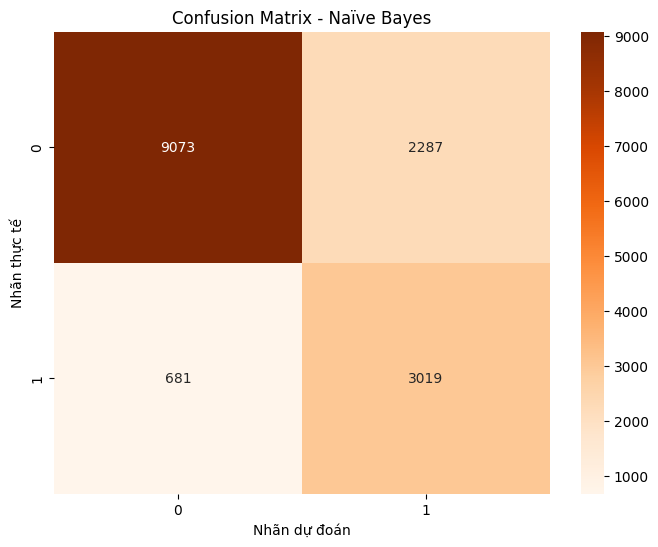

In [9]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

print("Ma trận nhầm lẫn Naïve Bayes:")
cm_nb = confusion_matrix(y_test, y_pred_nb)
print(cm_nb)

print("\nBáo cáo phân loại Naïve Bayes:")
print(classification_report(y_test, y_pred_nb))

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(
    y_test, y_pred_nb, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_nb, average="weighted", zero_division=0
))

plt.figure(figsize=(8, 6))
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Oranges")
plt.title("Confusion Matrix - Naïve Bayes")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.show()

Họ tên: Trần Thị Mỹ Dung
MSSV: 6451071008


,Mô hình,Accuracy,Precision,Recall,F1-score
0,ID3,0.815737,0.813992,0.815737,0.814817
1,CART,0.812948,0.811142,0.812948,0.811997
2,Naïve Bayes,0.802922,0.841440,0.802922,0.812998


<Figure size 1000x500 with 0 Axes>

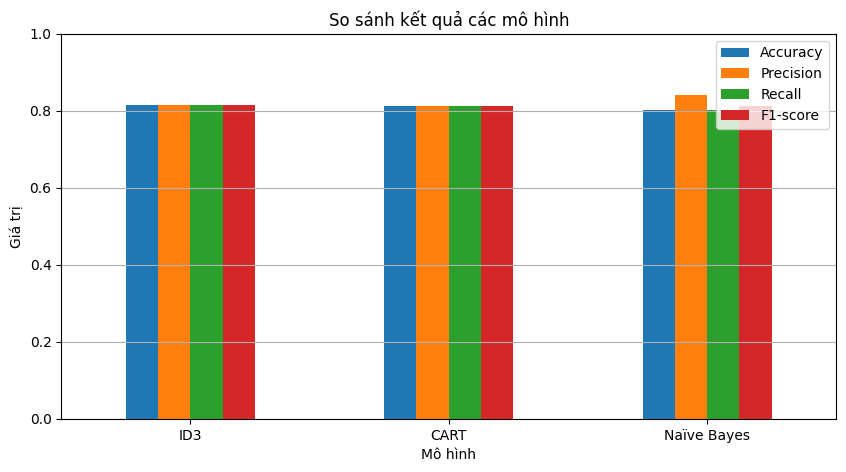

Mô hình có Accuracy cao nhất: ID3


In [10]:
print("Họ tên: Trần Thị Mỹ Dung")
print("MSSV: 6451071008")

results = pd.DataFrame({
    "Mô hình": ["ID3", "CART", "Naïve Bayes"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_id3),
        accuracy_score(y_test, y_pred_cart),
        accuracy_score(y_test, y_pred_nb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_id3, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_cart, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_nb, average="weighted", zero_division=0)
    ]
})

display(results)

plt.figure(figsize=(10, 5))
results.set_index("Mô hình")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("So sánh kết quả các mô hình")
plt.ylabel("Giá trị")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

best_model = results.loc[results["Accuracy"].idxmax(), "Mô hình"]
print("Mô hình có Accuracy cao nhất:", best_model)